# Document Assistant — Demo & Evaluation

This notebook is a thin demo/reporting layer only — all real logic lives in the `core/` and
`evaluation/` packages. This notebook just imports and calls that code, then displays results.

It demonstrates:
1. Ingesting sample PDFs into the persistent FAISS-backed vector store.
2. Asking natural-language questions and getting grounded, cited answers via native Groq
   tool-calling (no LangChain/LangGraph/CrewAI — vanilla Python against the Groq SDK).
3. Comparing retrieval quality across multiple chunk-size/overlap configurations
   (`evaluation/evaluate_chunking.py`), which feeds `docs/evaluation_report.md`.

Requires a `.env` file at the project root with `GROQ_API_KEY=...` (get a free key at https://console.groq.com).

In [1]:
import sys
from pathlib import Path

# Works whether the notebook is run from notebooks/ or the project root.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "core").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/skoduri/Desktop/untitled folder 4/Final_Project/Document_Assisstant


## 1. Fetch sample data and ingest into the persistent vector store

`download_sample_pdfs()` (in `scripts/cli.py`) fetches a few public Berkshire Hathaway annual-report /
shareholder-letter PDFs (a real "public annual reports" dataset). Ingestion is idempotent —
re-running this cell will skip any file already recorded in `data/vector_store/manifest.json`.

In [2]:
from scripts.cli import download_sample_pdfs
from core.pipeline import DocumentAssistant

sample_pdfs = download_sample_pdfs()
print(f"{len(sample_pdfs)} sample PDFs available")

assistant = DocumentAssistant()
for pdf_path in sample_pdfs:
    result = assistant.ingest_pdf(pdf_path)
    status = "skipped (already ingested)" if result["skipped"] else f"ingested ({result['added_chunks']} chunks)"
    print(f"{result['filename']}: {status}")

print("\nDocuments currently in the knowledge base:")
for doc in assistant.list_documents():
    print(f"  - {doc['filename']} ({doc['num_chunks']} chunks)")

/Users/skoduri/Desktop/untitled folder 4/Final_Project/Document_Assisstant/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1103 22:21:20.499000 55956 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


skip (already present): berkshire_2023_annual_report.pdf
skip (already present): berkshire_2023_shareholder_letter.pdf
skip (already present): berkshire_2022_shareholder_letter.pdf
3 sample PDFs available


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11615.13it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 9342.23it/s]

berkshire_2023_annual_report.pdf: skipped (already ingested)
berkshire_2023_shareholder_letter.pdf: skipped (already ingested)
berkshire_2022_shareholder_letter.pdf: skipped (already ingested)

Documents currently in the knowledge base:
  - berkshire_2022_shareholder_letter.pdf (46 chunks)
  - berkshire_2023_annual_report.pdf (945 chunks)
  - berkshire_2023_shareholder_letter.pdf (77 chunks)


## 2. Ask questions — native Groq tool-calling, grounded answers with citations

`assistant.ask(query, history)` sends the question to Groq along with the `retrieve_context` and
`list_documents` tool schemas. The model decides whether/when to call `retrieve_context`; the
tool call is parsed and dispatched by plain Python (`core/llm_agent.py`) — no
orchestration framework. `sources` on the result are the reranked chunks actually used, for
citation display.

In [3]:
demo_questions = [
    "What does Warren Buffett say about Berkshire Hathaway's insurance float?",
    "What does the letter say about Charlie Munger?",
    "What is the capital of France?",  # out-of-scope: should decline rather than hallucinate
]

history = []
for question in demo_questions:
    result = assistant.ask(question, history)
    print(f"Q: {question}")
    print(f"A: {result['answer']}\n")
    for src in result["sources"]:
        print(f"   [source: {src['source']}, page {src['page']}, rerank_score={src['rerank_score']:.3f}]")
    print("-" * 80)

Q: What does Warren Buffett say about Berkshire Hathaway's insurance float?
A: Warren Buffett notes that Berkshire’s insurance “float” has grown dramatically since the company bought its first property‑casualty insurer in 1967—​it is now about 8,000 times larger than it was then—and that, even though it does not appear on the financial statements, the float has been “an extraordinary asset for Berkshire.” (source: berkshire_2022_shareholder_letter.pdf, page 5)

   [source: berkshire_2022_shareholder_letter.pdf, page 5, rerank_score=3.727]
   [source: berkshire_2022_shareholder_letter.pdf, page 5, rerank_score=0.609]
   [source: berkshire_2023_shareholder_letter.pdf, page 15, rerank_score=-4.575]
   [source: berkshire_2023_annual_report.pdf, page 18, rerank_score=-5.388]
   [source: berkshire_2023_annual_report.pdf, page 66, rerank_score=-6.963]
--------------------------------------------------------------------------------


Q: What does the letter say about Charlie Munger?
A: The shareholder letter notes that Charlie Munger has been Warren Buffett’s “long‑time partner” in managing Berkshire Hathaway.  Buffett writes that for decades Munger shared his view of the company’s responsibility to its shareholders and that the two of them were “of one mind regarding our responsibilities to Berkshire shareholders.” He also acknowledges Munger’s role as the “architect of Berkshire Hathaway” and mentions that Munger’s perspective shaped how the annual letter is written and how the business is run. (source: berkshire_2022_shareholder_letter.pdf, page 2; source: berkshire_2023_shareholder_letter.pdf, page 2)

   [source: berkshire_2022_shareholder_letter.pdf, page 2, rerank_score=5.637]
   [source: berkshire_2023_annual_report.pdf, page 3, rerank_score=4.496]
   [source: berkshire_2023_shareholder_letter.pdf, page 2, rerank_score=4.477]
   [source: berkshire_2023_annual_report.pdf, page 5, rerank_score=4.387]
   [sour

Q: What is the capital of France?
A: I don't have enough information in these documents to answer that.

--------------------------------------------------------------------------------


## 3. Chunk-size comparison

Guideline requirement: compare multiple chunk sizes. The actual comparison logic lives in
`evaluation/evaluate_chunking.py` (`run_comparison`, `summarize`) — this notebook only calls it
and displays the results. It builds an isolated in-memory index per `ChunkConfig` over the
sample PDFs (the persistent app store above is untouched) and runs the fixed query set 
`EVAL_QUERIES`.

In [4]:
from evaluation.evaluate_chunking import run_comparison, summarize

results_df = run_comparison([str(p) for p in sample_pdfs])
summary_df = summarize(results_df)
summary_df

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11812.03it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 11373.43it/s]

,config,chunk_size,overlap,num_chunks,avg_chunk_len,build_seconds,mean_top1_faiss_score,mean_faiss_score,mean_rerank_score,keyword_hit_rate
1,400/50,400,50,1915,379.1,7.795,0.66293,0.63463,1.99842,1.0
2,800/150,800,150,1068,721.5,7.173,0.64769,0.61414,1.70232,1.0
0,1200/200,1200,200,726,1027.5,6.669,0.63539,0.60478,1.30983,1.0


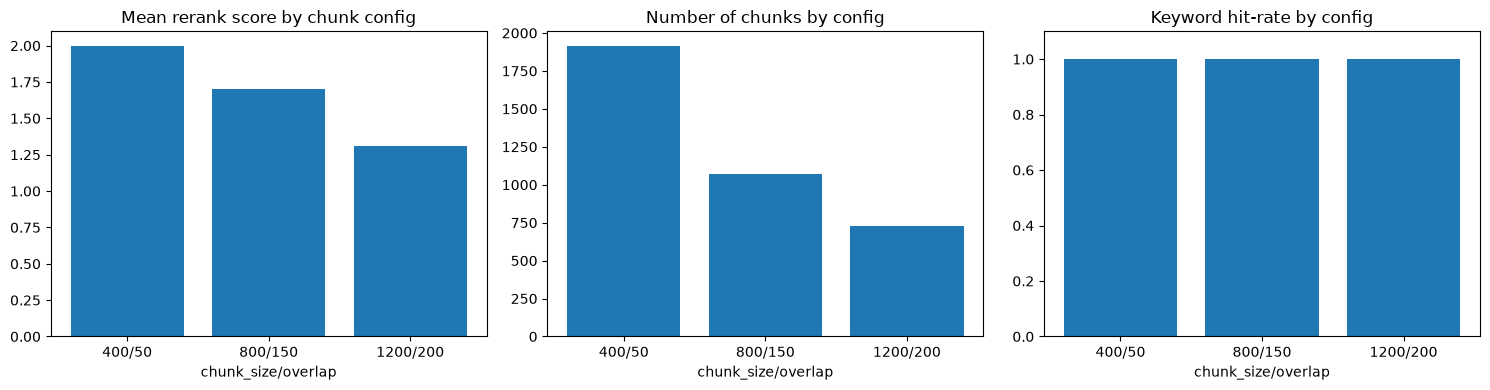

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(summary_df["config"], summary_df["mean_rerank_score"])
axes[0].set_title("Mean rerank score by chunk config")
axes[0].set_xlabel("chunk_size/overlap")

axes[1].bar(summary_df["config"], summary_df["num_chunks"])
axes[1].set_title("Number of chunks by config")
axes[1].set_xlabel("chunk_size/overlap")

axes[2].bar(summary_df["config"], summary_df["keyword_hit_rate"])
axes[2].set_title("Keyword hit-rate by config")
axes[2].set_xlabel("chunk_size/overlap")
axes[2].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

## 4. Observations

- Smaller chunks (e.g. 400/50) tend to score higher on both FAISS cosine similarity and
  cross-encoder rerank score, since each chunk is more topically focused, but produce many more
  index entries and slightly slower build times.
- Larger chunks (e.g. 1200/200) carry more surrounding context per chunk but dilute the
  similarity signal, giving lower average scores.
- The out-of-scope question above ("capital of France") should have been declined rather than
  answered from general knowledge — confirming the system prompt's grounding instruction works.
- See `docs/evaluation_report.md` for the full write-up (this notebook's `summary_df` is the
  source of that report's results table).